# Анализ и прогнозирование временных рядов методами искусственного интеллекта

## **Практическая работа 4. Матричный профиль. Поиск примитивов на его основе.**

Смените рабочую директорию с помощью команды `chdir()`. Для этого передайте этой команде свой путь до каталога, в котором содержатся материалы четвертой практической работы. После выполнения этой команды все последующие операции с файлами и каталогами будут производиться относительно указанного каталога.

Выполните команды, которые автоматически перезагружают все импортированные модули при их изменении.

In [1]:
%load_ext autoreload
%autoreload 2

Импортируйте библиотеки и модули, необходимые для реализации практической работы 4.

In [2]:
import pandas as pd
import numpy as np
import os
import datetime

from modules.plots import *
from modules.mp import compute_mp
from modules.motifs import top_k_motifs
from modules.discords import top_k_discords
from modules.meter_swapping_detection import *

d:\Venvs\.dm_venv\Lib\site-packages\stumpy\__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


## **Часть 1.** Матричный профиль. Поиск мотивов и диссонансов.

### **Задача 1.**
Загрузите временной ряд, который содержит данные о почасовом потреблении электроэнергии некоторого итальянского города, снимаемые в течение 3 лет, начиная с 1 января 1995 года.

In [3]:
ts_url = './datasets/part1/italianpowerdemand.csv'
ts = pd.read_csv(ts_url, header=None).squeeze().to_numpy()

Визуализируйте временной ряд, используя функцию `plot_ts()` из модуля *plot.py*.

In [4]:
plot_ts(ts, "Input time series")

Анализ временных рядов на основе матричного профиля осуществляет библиотека [stumpy](https://stumpy.readthedocs.io/en/latest/index.html). Напишите функцию `compute_mp()` в модуле *mp.py*, которая вычисляет матричный профиль временного ряда на основе выбранной вами функции из библиотеки *stumpy*.

In [5]:
m = 165
excl_zone = int(np.ceil(m / 2))
mp = compute_mp(ts, m, excl_zone)

Визуализируйте найденный матричный профиль ряда.

In [6]:
plot_ts(mp['mp'], "Matrix Profile")

### **Задача 2.**
Выполните поиск top-$k$ мотивов в исходном временном ряде на основе построенного матричного профиля. Для этого реализуйте самостоятельно функцию `top_k_motifs()` в модуле *motifs.py*. Среди найденных мотивов не должно быть тривиальных совпадений, поэтому в `top_k_motifs()` добавьте вызов функции `apply_exclusion_zone()` из модуля *utils.py*.

In [7]:
top_k = 6
motifs = top_k_motifs(mp, top_k)
motifs

{'indices': [(np.int64(17852), np.int64(18188)),
  (np.int64(18539), np.int64(27276)),
  (np.int64(19168), np.int64(28073)),
  (np.int64(18208), np.int64(26945)),
  (np.int64(19343), np.int64(28080)),
  (np.int64(18611), np.int64(18779))],
 'distances': [np.float64(1.2266251888823534),
  np.float64(1.2356334381445964),
  np.float64(1.2455578192682446),
  np.float64(1.245796504554174),
  np.float64(1.2715944340228518),
  np.float64(1.3080603082095197)]}

Выполните визуализацию найденных top-$k$ мотивов с помощью функции `plot_motifs()` из *plots.py*.

In [8]:
plot_motifs(mp, motifs)

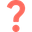
Проанализируйте и изложите содержательный смысл полученных результатов.

Длина подпоследовательности 165 примерно равна 1 неделе.

Были найдены повторяющиеся шаблоны потребления электорэнергии. Это может быть связано с временем года или другими факторами.

### **Задача 3.**
Реализуйте самостоятельно функцию `top_k_discords()` в модуле *discords.py*, предназначенную для поиска top-$k$ диссонансов во временном ряде на основе матричного профиля. Чтобы исключить попадание тривиальных совпадений в результирующее множество диссонансов воспользуйтесь функцией `apply_exclusion_zone()` из модуля *utils.py*.

Загрузите временной ряд *nyc_taxi.csv* из директории *./datasets/part1/*, содежащий данные о среднем числе пассажиров NY такси за осень 2014 года.

In [9]:
ts_url = './datasets/part1/nyc_taxi.csv'

ts = pd.read_csv(ts_url, index_col=0, header=0).squeeze().to_numpy()
plot_ts(ts, "Input time series")

In [10]:
ts = ts.astype(np.float64)

In [11]:
m = 96
excl_zone = int(np.ceil(m / 2))
mp = compute_mp(ts, m, excl_zone)
plot_ts(mp["mp"], "Matrix profile for NYC taxi.")

In [12]:
top_k = 15
discords = top_k_discords(mp, top_k)

Выполните визуализацию найденных top-$k$ диссонансов.

In [13]:
plot_discords(mp, discords)

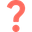
Проанализируйте и изложите содержательный смысл полученных результатов.

Найденные диссонансы могут соответсвовать выходным дням, потому что обычно число пассжиров такси в выходные дни меньше, чем в рабочие дни, праздничным дням, потому что обычно в такие дни число пассажиров такси больше, чем в рабочие дни, или глобальным событиям.

## **Часть 2.** Сегментация повторяющихся активностей.

### **Задача 4.**

Загрузите временной ряд PAMAP *pamap.csv* из директории *./datasets/part2/*, представляющий собой показания закрепленного на человеке виброакселерометра. Данный ряд включает показания, снятые при выполнении человеком трех видов физической активности: ходьба, подъем по лестнице и спуск по лестнице. Необходимо сегментировать временной ряд на основе его матричного профиля для определения того, когда человек шел и когда поднимался/спускался. Поскольку подъем и спуск по лестнице – это схожие действия, поэтому будем считать, что это одна активность.  

In [14]:
ts_url = './datasets/part2/pamap.csv'
ts = pd.read_csv(ts_url, header=None).squeeze().to_numpy()
ts.shape

(31000,)

Визуализируйте временной ряд PAMAP.

In [15]:
plot_ts(ts, "Input time series")

Найдите и визуализируйте матричный профиль временного ряда.

In [16]:
m = 100
excl_zone = m
mp = compute_mp(ts, m, excl_zone)

In [17]:
plot_ts(mp['mp'], "Matrix Profile")

Вычислите порог по формуле, которая представлена в презентации [04 Matrix profile.pdf](https://github.com/mzym/TimeSeriesCourse/blob/main/slides/04%20Matrix%20profile.pdf).

In [18]:
mp2 = mp["mp"]
mp2 = mp2[np.isfinite(mp2)]
threshold = 0.55 * (mp2.min() + mp2.max())
threshold

np.float64(6.8708136351274876)

Выполните визуализацию результатов сегментации повторяющихся активностей.

In [19]:
plot_segmentation(mp, threshold)

Загрузите истинную разметку временного ряда PAMAP *pamap_labels.csv*, где 0 означает ходьбу, 1 – подъем по лестнице, 2 – спуск с лестницы. Вычислите точность по метрике accuracy, сравнив полученные результаты по основе матричного профиля с истинной разметкой.

In [20]:
labels_url = './datasets/part2/pamap_labels.csv'
labels = pd.read_csv(labels_url, header=None).squeeze().to_numpy()
labels

array([2, 2, 2, ..., 1, 1, 1], shape=(31000,))

In [21]:
P = mp["mp"]
I = mp["mpi"]
m = mp["m"]

# Считаем, что спуск и подъём по лестнице - это одно и то же.
# Ходьюа - 0, спуск/подъем по лестнице - 1.
n = ts.shape[0]
pred = np.zeros(ts.shape)
for i in range(n - m):
    if P[i] < threshold:
        pred[i] = 1
    else:
        pred[i] = 0
pred[n - m:] = pred[n - m - 1]

true = np.where(labels == 0, 0, 1)
accuracy = (true == pred).sum() / n
print(f"Accuracy: {accuracy:.3f}")

Accuracy: 0.933


In [22]:
import matplotlib.pyplot as plt

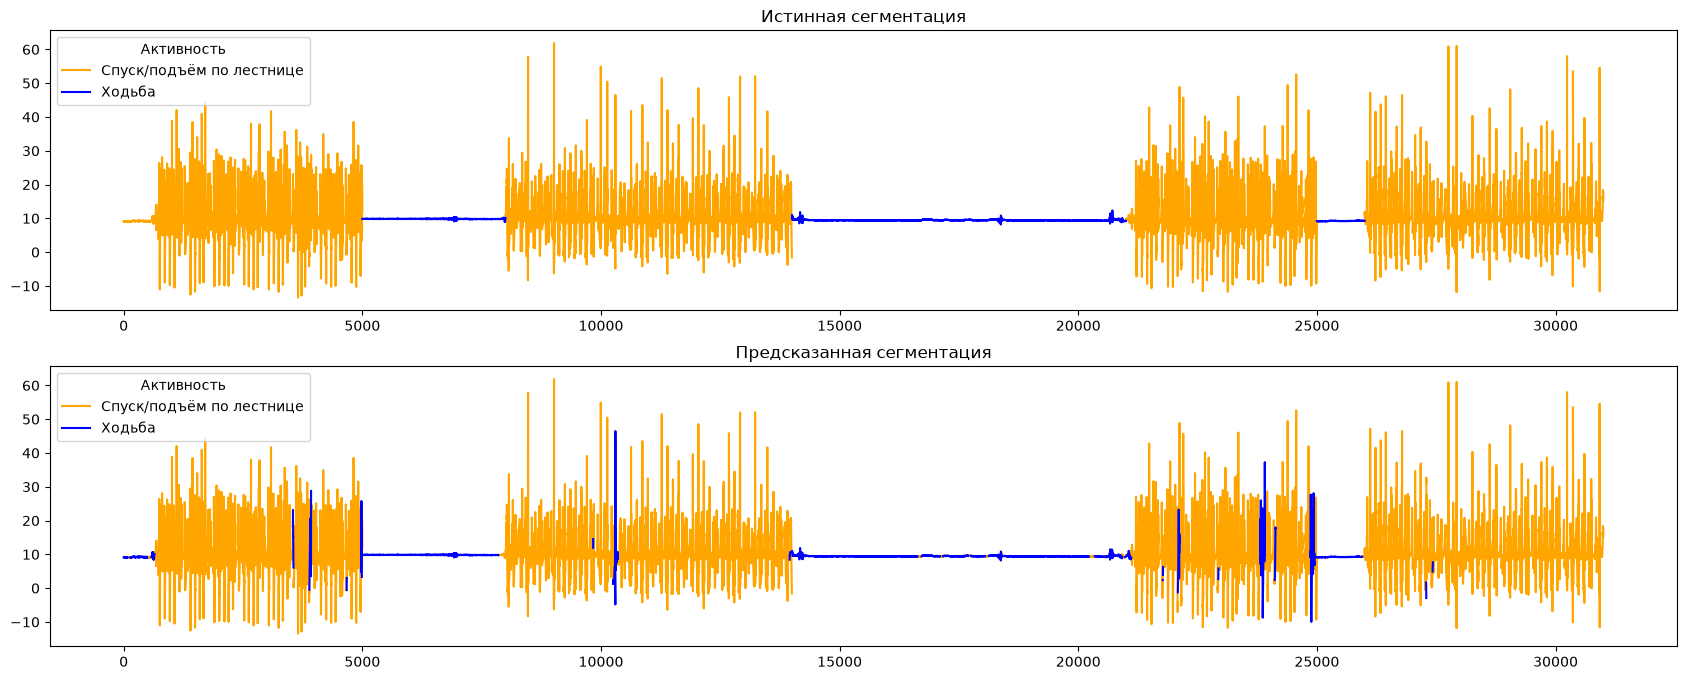

In [23]:
rows = 2
cols = 1
fig = plt.figure(figsize=(21, 4 * rows))

colors = {
    0: "blue",
    1: "orange"
}
x = np.arange(n)

ax = fig.add_subplot(rows, cols, 1)
s0 = np.where(true == 0, ts, np.nan)
s1 = np.where(true == 1, ts, np.nan)
ax.plot(x, s1, color=colors[1], label="Спуск/подъём по лестнице")
ax.plot(x, s0, color=colors[0], label="Ходьба")
ax.set_title("Истинная сегментация")
ax.legend(title="Активность")

ax = fig.add_subplot(rows, cols, 2)
s0 = np.where(pred == 0, ts, np.nan)
s1 = np.where(pred == 1, ts, np.nan)
ax.plot(x, s1, color=colors[1], label="Спуск/подъём по лестнице")
ax.plot(x, s0, color=colors[0], label="Ходьба")
ax.set_title("Предсказанная сегментация")
ax.legend(title="Активность")

plt.show()

## **Чaсть 3.** Casy Study: Раскрытие краж электричества подменой счетчиков (meter-swapping detection).


### **Задача 5.**

Рассмотрим практическое применение использования матричного профиля для решения задачи, связанной с раскрытием краж электричества путем подмены счетчиков.

Загрузите временные ряды из директории *./datasets/part3/*, которые были выбраны случайным образом из набора данных (House 1, 2, 3, 4 и 11), содержащего данные потребления электроэнергии 20 жилых домов в Великобритании с 1 января по 23 декабря 2014 года.

In [24]:
path = './datasets/part3/'

house_idx = [1, 2, 3, 4, 11]

filenames = [f"House{i}.csv" for i in house_idx]

consumptions = {}
for house in filenames:
    consumptions[house[:-4]] = pd.read_csv(os.path.join(path, house), header=None, index_col=0)
    consumptions[house[:-4]].index = pd.to_datetime(consumptions[house[:-4]].index, format="mixed", dayfirst=True)

Далее смоделируем событие замены счетчика. Для этого каждый временной ряд разделим на две части: "Head" (до 1 октября) и "Tail" (после 1 октября). После чего выберем случайным образом 2 временных ряда (например, House1 и House11) и поменяем местами их "Tail" части.

In [25]:
cutoff = pd.to_datetime('2014-10-01')
heads, tails = heads_tails(consumptions, cutoff, house_idx)

#swap Heads and Tails of 1 and 11
swap1, swap2 = 1, 11
consumptions[f'House{swap1}'] = pd.concat([heads[f'H_{swap1}'], tails[f'T_{swap2}']]) 
consumptions[f'House{swap2}'] = pd.concat([heads[f'H_{swap2}'], tails[f'T_{swap1}']])
# consumptions[f'House{swap1}'] = heads[f'H_{swap1}'].append(tails[f'T_{swap2}'])
# consumptions[f'House{swap2}'] = heads[f'H_{swap2}'].append(tails[f'T_{swap1}'])
heads, tails = heads_tails(consumptions, cutoff, house_idx)

In [26]:
heads

{'H_1':                                1
 0                               
 2014-01-01 00:00:00  1422.005576
 2014-01-01 01:00:00  1707.948669
 2014-01-01 02:00:00  1442.025253
 2014-01-01 03:00:00  1374.657191
 2014-01-01 04:00:00  1757.285235
 ...                          ...
 2014-09-30 19:00:00   183.115942
 2014-09-30 20:00:00   235.133945
 2014-09-30 21:00:00   181.379747
 2014-09-30 22:00:00   200.409009
 2014-09-30 23:00:00   185.529081
 
 [6552 rows x 1 columns],
 'H_2':                                1
 0                               
 2014-02-13 16:00:00   783.505155
 2014-02-13 17:00:00          NaN
 2014-02-13 18:00:00          NaN
 2014-02-13 19:00:00   241.000000
 2014-02-13 20:00:00  1102.175000
 ...                          ...
 2014-09-30 19:00:00   592.727924
 2014-09-30 20:00:00   344.297619
 2014-09-30 21:00:00   376.567033
 2014-09-30 22:00:00  1043.671024
 2014-09-30 23:00:00   616.574561
 
 [5504 rows x 1 columns],
 'H_3':                               1
 0    

In [27]:
tails

{'T_1':                                1
 0                               
 2014-10-01 00:00:00   178.098174
 2014-10-01 01:00:00   173.544218
 2014-10-01 02:00:00   127.820046
 2014-10-01 03:00:00   352.545012
 2014-10-01 04:00:00    78.065104
 ...                          ...
 2014-12-30 19:00:00   178.684008
 2014-12-30 20:00:00   458.040777
 2014-12-30 21:00:00  1024.073501
 2014-12-30 22:00:00   237.409709
 2014-12-30 23:00:00   332.056202
 
 [2184 rows x 1 columns],
 'T_2':                               1
 0                              
 2014-10-01 00:00:00  126.636761
 2014-10-01 01:00:00   90.670330
 2014-10-01 02:00:00  120.361656
 2014-10-01 03:00:00  119.541475
 2014-10-01 04:00:00   89.609137
 ...                         ...
 2014-12-30 19:00:00  138.643810
 2014-12-30 20:00:00   95.211429
 2014-12-30 21:00:00  119.654649
 2014-12-30 22:00:00  157.086304
 2014-12-30 23:00:00   83.236742
 
 [2184 rows x 1 columns],
 'T_3':                                1
 0                

Визуализируйте исходные временные ряды и параллельную оси OY прямую, которая делит временные ряды на "Head" и "Tail" части.

In [28]:
plot_consumptions_ts(consumptions, cutoff, house_idx)

Чтобы найти переставленную пару временных рядов, выполним следующее. Сначала составим временные ряды $H_i$ из всевозможных комбинаций "Head" и "Tail" частей исходных временных рядов $T_K$, где $1 \leq i \leq |T|^2$, $1 \leq K \leq |T|$. В нашем случае, $|T| = 5$.  Далее среди них найдем такую пару временных рядов $(H_i, H_j)$, которая имеет минимальную оценку $swap\_score$. Минимальная оценка $swap\_score$ для пары рядов $(H_i, H_j)$ вычисляется следующим образом:

\begin{equation}
swap\_score(i,j) = \frac{\min{(Head_{H_i} \bowtie Tail_{H_j})}}{\min{(Head_{H_i} \bowtie Tail_{H_i})}+eps},
\end{equation}

где $\bowtie$ – операция нахождения матричного профиля между двумя временными рядами. Матричный профиль между двумя временными рядами содержит расстояния между всеми подпоследовательностями первого временного ряда и их ближайшими соседями, которые являются подпоследовательностями второго временного ряда.

Добавьте в функцию `compute_mp()` в модуле *mp.py* поддежку вычисления матричного профиля между двумя различными временными рядами и найдите пару временных рядов $(H_i, H_j)$, которая имеет минимальную оценку $swap\_score$ среди всех пар.

In [29]:
m = 24 * 4
min_score = meter_swapping_detection(heads, tails, house_idx, m)

In [30]:
min_i, min_j, mp_j = min_score['i'], min_score['j'], min_score['mp_j']
print(f'Time series with minimum score is (H_{min_i}, T_{min_j}).')

Time series with minimum score is (H_11, T_1).


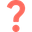
Проанализируйте и изложите содержательный смысл полученных результатов.

В результате работы алгоритма временные ряды $H_{11}$ и $H_1$ имеют минимальное значение swap_score. Значит, что счетчик дома 11 был подменен счетчиком дома 1, то есть дом 1 крадет электричество у дома 11.